# Comparação do ajuste de ruído: simulação × hardware real

Este notebook lê as pastas `resultados/*_analise` geradas pelo `07_analisar_lote.py` e
mostra, em gráficos simples, se a simulação se parece com o hardware da IBM, com e sem o ajuste.

**Como usar:** rode as células de cima para baixo (*Kernel → Restart & Run All*).
Não precisa de Qiskit nem de internet, só de `numpy` e `matplotlib`.

## Como ler os gráficos

| Termo | O que é |
|---|---|
| **Real** | Resultado do hardware da IBM. Nunca é alterado pelo ajuste. |
| **N0** | Simulação com a calibração da IBM, sem ajuste. |
| **N1** | Simulação com os 6 multiplicadores ajustados no GHZ-5. |
| **Massa GHZ** | Fração dos shots que saiu `00…0` ou `11…1` (o resultado certo). O ideal é 100%. |
| **Erro da massa** | Diferença, em pontos percentuais (pp), entre a massa simulada e a real. Quanto menor, melhor. |
| **Hellinger** | Distância entre as distribuições inteiras: 0 = iguais, 1 = nada em comum. Quanto menor, melhor. |
| **Piso** | Menor Hellinger possível só por causa do sorteio de 1000 shots (duas simulações do N0 com seeds diferentes). |
| **Variação do hardware** | Hellinger entre dois jobs reais do mesmo circuito. Só existe com 2 ou mais repetições. |
| **Bits errados** | Quantos bits de um shot diferem do `00…0` ou do `11…1` mais próximo. No GHZ ideal é sempre 0. |

In [1]:
import json
import re
import datetime as _dt
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10,
})
COR = {"real": "#333333", "N0": "#E69F00", "N1": "#0072B2"}   # paleta que funciona para daltonismo
NOME = {"real": "Real (IBM)", "N0": "N0 (calibração)", "N1": "N1 (ajustado)"}


def achar_pasta_resultados():
    aqui = Path.cwd().resolve()
    for p in [aqui, *aqui.parents]:
        for cand in (p / "resultados", p / "quantum-modeling" / "resultados"):
            if cand.is_dir():
                return cand
    raise FileNotFoundError("Não achei a pasta 'resultados'. Abra o notebook dentro de quantum-modeling/.")


RESULTADOS = achar_pasta_resultados()
DISPONIVEIS = sorted(p for p in RESULTADOS.glob("*_analise") if (p / "resultados.json").exists())
print("Pasta:", RESULTADOS)
print("Rodadas encontradas:")
for p in DISPONIVEIS:
    print("  ", p.name)

Pasta: C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados
Rodadas encontradas:
   2026-11-22_1616_lote_aprendizado_analise
   2026-11-23_1421_lote_aprendizado_02_analise


In [2]:
# Quais rodadas comparar.
#   None  -> usa todas as rodadas encontradas (da mais antiga para a mais nova)
#   ou uma lista com os nomes das pastas, por exemplo:
#   ESCOLHA = ["2026-11-22_1616_lote_aprendizado_analise", "2026-11-23_1500_lote_aprendizado_02_analise"]
ESCOLHA = None

# Nomes bonitos opcionais para os gráficos: {"nome_da_pasta": "ontem"}
ROTULOS = {}

FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(exist_ok=True)

pastas = DISPONIVEIS if ESCOLHA is None else [RESULTADOS / n for n in ESCOLHA]
assert pastas, "Nenhuma rodada para analisar."

In [3]:
def bits_errados(dist):
    """Dobra a distribuição de pesos de Hamming: bits fora do GHZ mais próximo (00..0 ou 11..1)."""
    n = len(dist) - 1
    saida = np.zeros(n // 2 + 1)
    for w, p in enumerate(dist):
        saida[min(w, n - w)] += p
    return saida


def incerteza(valores, shots):
    """Barra de incerteza: desvio entre repetições; com 1 repetição, o desvio do sorteio de shots."""
    v = np.asarray(valores, dtype=float)
    if len(v) > 1:
        return float(np.std(v, ddof=1))
    p = float(v[0])
    return float(np.sqrt(max(p * (1 - p), 0) / shots))


def carregar_rodada(pasta):
    linhas = json.loads((pasta / "resultados.json").read_text(encoding="utf-8"))
    mp = pasta / "manifesto.json"
    man = json.loads(mp.read_text(encoding="utf-8")) if mp.exists() else {}
    por = {}
    for l in linhas:
        if l.get("tipo") == "ghz":
            por.setdefault(l["circuito"], []).append(l)
    circ = {}
    for nome, ls in sorted(por.items(), key=lambda kv: kv[1][0]["n"]):
        ls.sort(key=lambda l: l["repeticao"])

        def pega(f):
            return np.array([f(l) for l in ls], dtype=float)

        def ham(chave, lado):
            return np.mean([bits_errados(l[chave][lado]["distribuicao_peso_hamming"]) for l in ls], axis=0)

        circ[nome] = {
            "n": ls[0]["n"], "reps": len(ls), "shots": ls[0]["nivel0"]["real"]["shots"],
            "ajuste": any(l.get("conjunto") == "ajuste" for l in ls),
            "massa": {"real": pega(lambda l: l["nivel0"]["real"]["massa_ghz"]),
                      "N0": pega(lambda l: l["nivel0"]["simulado"]["massa_ghz"]),
                      "N1": pega(lambda l: l["nivel1"]["simulado"]["massa_ghz"])},
            "H": {"N0": pega(lambda l: l["nivel0"]["hellinger"]), "N1": pega(lambda l: l["nivel1"]["hellinger"])},
            "piso": pega(lambda l: l["hellinger_sim_x_sim"]),
            "hw": (man.get("hellinger_hardware_x_hardware") or {}).get(nome),
            "bits": {"real": ham("nivel0", "real"), "N0": ham("nivel0", "simulado"), "N1": ham("nivel1", "simulado")},
        }
    nreps = max((d["reps"] for d in circ.values()), default=0)
    m = pasta.name.split("_")
    try:
        data = _dt.datetime.strptime(m[0], "%Y-%m-%d").strftime("%d/%m")
    except ValueError:
        data = pasta.name[:10]
    rotulo = ROTULOS.get(pasta.name, f"{data} · {man.get('modo_ajuste', '?')} · {nreps} rep.")
    return rotulo, circ, man


RODADAS = {}
for p in pastas:
    r, c, m = carregar_rodada(p)
    if r in RODADAS:
        r = f"{r} ({p.name[11:15]})"
    RODADAS[r] = {"circ": c, "man": m, "pasta": p}
print("Rodadas carregadas:", list(RODADAS))


def erro_massa_pp(d, modelo):
    """Erro da massa GHZ em pontos percentuais (média entre repetições)."""
    return float(np.mean(np.abs(d["massa"][modelo] - d["massa"]["real"])) * 100)


def salvar(fig, nome):
    nome = re.sub(r"[^A-Za-z0-9_-]+", "", nome.replace("·", "_").replace(" ", "")).strip("_.")
    caminho = FIGURAS / f"{nome}.png"
    fig.savefig(caminho, dpi=200, bbox_inches="tight")
    print("figura salva em", caminho)

Rodadas carregadas: ['22/11 · rapido · 1 rep.', '23/11 · completo · 3 rep.']


## 1. Tabela resumo

In [12]:
for rot, R in RODADAS.items():
    print(f"\n=== {rot} ===")
    print(f"{'circuito':<11}{'massa real':>11}{'N0':>8}{'N1':>8}{'erro N0':>10}{'erro N1':>10}{'H N0':>8}{'H N1':>8}")
    for nome, d in R["circ"].items():
        m = {k: float(np.mean(v)) for k, v in d["massa"].items()}
        hw = f"{d['hw']:.3f}" if d["hw"] is not None else "-"
        marca = "*" if d["ajuste"] else " "
        print(f"{nome + marca:<11}{m['real']:>11.1%}{m['N0']:>8.1%}{m['N1']:>8.1%}"
              f"{erro_massa_pp(d, 'N0'):>8.1f}pp{erro_massa_pp(d, 'N1'):>8.1f}pp"
              f"{np.mean(d['H']['N0']):>8.3f}{np.mean(d['H']['N1']):>8.3f}")
    print("* circuito usado no ajuste. 'erro' = diferença da massa GHZ em relação ao real, em pontos percentuais.")


=== 22/11 · rapido · 1 rep. ===
circuito    massa real      N0      N1   erro N0   erro N1    H N0    H N1
ghz_n05*         90.3%   90.7%   86.6%     0.4pp     3.7pp   0.143   0.120
ghz_n20          52.8%   64.1%   56.2%    11.3pp     3.4pp   0.446   0.429
ghz_n40          26.5%   37.5%   27.3%    11.0pp     0.8pp   0.677   0.716
* circuito usado no ajuste. 'erro' = diferença da massa GHZ em relação ao real, em pontos percentuais.

=== 23/11 · completo · 3 rep. ===
circuito    massa real      N0      N1   erro N0   erro N1    H N0    H N1
ghz_n05*         88.5%   94.0%   92.3%     5.5pp     3.8pp   0.137   0.101
ghz_n20          60.1%   75.1%   68.6%    15.0pp     8.5pp   0.381   0.337
ghz_n40          30.6%   47.0%   44.4%    16.4pp    13.8pp   0.650   0.620
* circuito usado no ajuste. 'erro' = diferença da massa GHZ em relação ao real, em pontos percentuais.


## 2. Massa GHZ: real × N0 × N1

Barras = média das repetições. As linhas pretas são a incerteza: o desvio entre repetições
ou, quando há só uma, o desvio esperado do sorteio de 1000 shots.
Quanto mais perto da barra cinza (real), melhor.

figura salva em C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados\figuras\massa_22-11_rapido_1rep.png


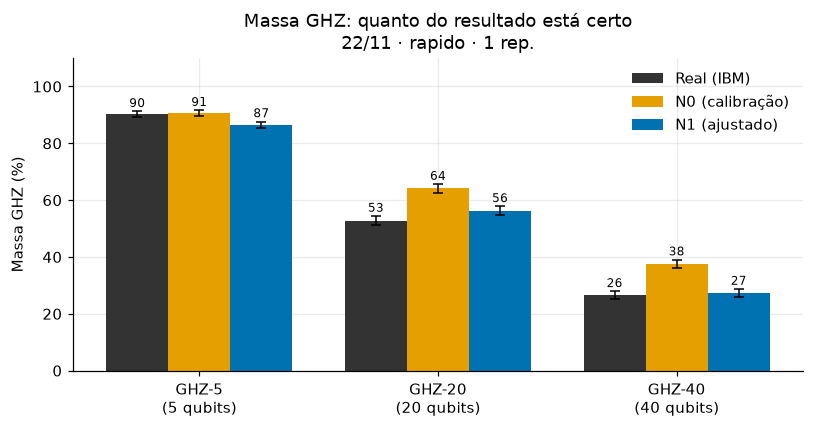

figura salva em C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados\figuras\massa_23-11_completo_3rep.png


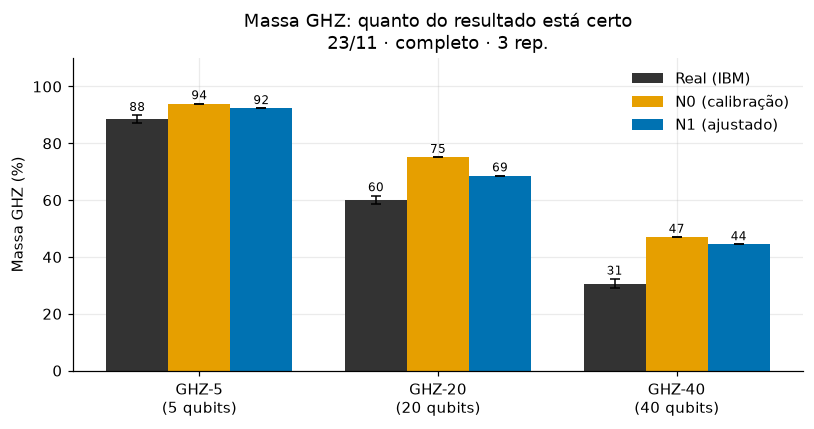

In [5]:
for rot, R in RODADAS.items():
    circ = R["circ"]
    nomes = list(circ)
    x = np.arange(len(nomes))
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for k, modelo in enumerate(["real", "N0", "N1"]):
        medias = [np.mean(circ[n]["massa"][modelo]) * 100 for n in nomes]
        barras = [incerteza(circ[n]["massa"][modelo], circ[n]["shots"]) * 100 for n in nomes]
        ax.bar(x + (k - 1) * 0.26, medias, 0.26, yerr=barras, capsize=3, color=COR[modelo], label=NOME[modelo],
               error_kw={"elinewidth": 1, "ecolor": "black"})
        for xi, v, b in zip(x + (k - 1) * 0.26, medias, barras):
            ax.text(xi, v + b + 1.5, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([f"GHZ-{circ[n]['n']}\n({circ[n]['n']} qubits)" for n in nomes])
    ax.set_ylabel("Massa GHZ (%)")
    ax.set_ylim(0, 110)
    ax.set_title(f"Massa GHZ: quanto do resultado está certo\n{rot}")
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    salvar(fig, f"massa_{rot.replace('/', '-').replace(' ', '').replace('·', '_')}")
    plt.show()

## 3. Erro da massa: quanto cada modelo erra

É a comparação mais direta: a distância, em pontos percentuais, entre a massa simulada e a real.
Se o N1 tem barra menor que o N0, o ajuste ajudou naquele circuito.

figura salva em C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados\figuras\erro_massa.png


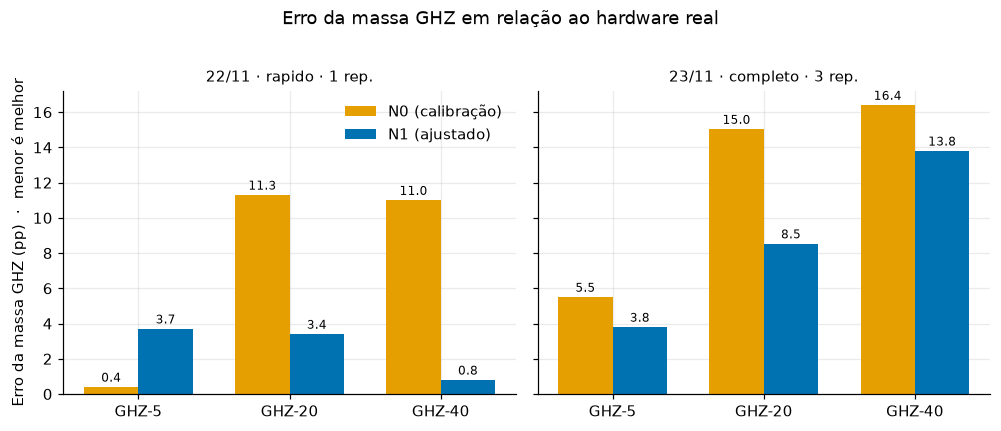

In [6]:
fig, eixos = plt.subplots(1, len(RODADAS), figsize=(4.6 * len(RODADAS), 3.8), sharey=True, squeeze=False)
for ax, (rot, R) in zip(eixos[0], RODADAS.items()):
    nomes = list(R["circ"])
    x = np.arange(len(nomes))
    for k, modelo in enumerate(["N0", "N1"]):
        v = [erro_massa_pp(R["circ"][n], modelo) for n in nomes]
        ax.bar(x + (k - 0.5) * 0.36, v, 0.36, color=COR[modelo], label=NOME[modelo])
        for xi, vi in zip(x + (k - 0.5) * 0.36, v):
            ax.text(xi, vi + 0.3, f"{vi:.1f}", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(["GHZ-" + str(int(n.split("n")[-1])) for n in nomes])
    ax.set_title(rot, fontsize=10)
eixos[0][0].set_ylabel("Erro da massa GHZ (pp)  ·  menor é melhor")
eixos[0][0].legend(frameon=False)
fig.suptitle("Erro da massa GHZ em relação ao hardware real", y=1.02)
fig.tight_layout()
salvar(fig, "erro_massa")
plt.show()

## 4. Multiplicadores ajustados

Cada ponto é o valor encontrado pelo algoritmo. A linha vertical em **1** é a calibração da IBM sem alteração.
A linha cinza horizontal mostra a faixa permitida. Um ponto **encostado numa ponta** indica que o algoritmo
queria ir além do limite, ou que aquele parâmetro quase não influencia o resultado.

figura salva em C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados\figuras\multiplicadores.png


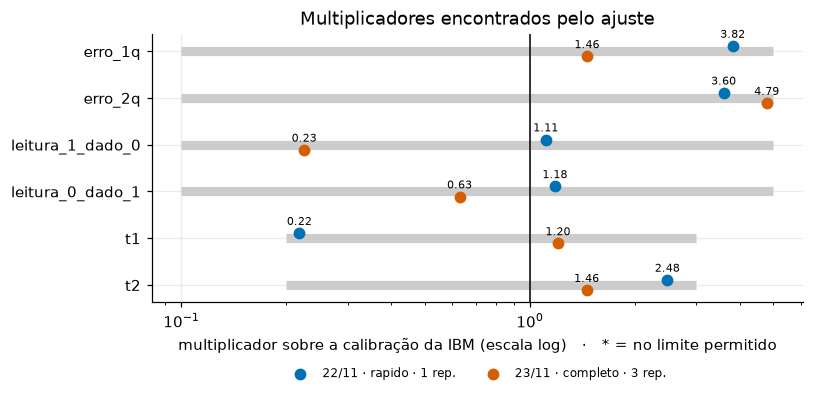

In [7]:
cores = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#F0E442"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
genes = None
for i, (rot, R) in enumerate(RODADAS.items()):
    man = R["man"]
    if not man.get("escalas_ajustadas"):
        continue
    genes = man["genes"]
    lims = man["limites"]
    vals = [man["escalas_ajustadas"][g] for g in genes]
    y = np.arange(len(genes)) + (i - (len(RODADAS) - 1) / 2) * 0.22
    if i == 0:
        for yy, (lo, hi) in zip(np.arange(len(genes)), lims):
            ax.hlines(yy, lo, hi, color="#cccccc", lw=6, zorder=1)
    ax.scatter(vals, y, color=cores[i % len(cores)], s=45, zorder=3, label=rot)
    for v, yy, (lo, hi) in zip(vals, y, lims):
        encostado = (v <= lo * 1.02) or (v >= hi * 0.98)
        ax.text(v, yy - 0.12, f"{v:.2f}" + (" *" if encostado else ""), ha="center", va="bottom", fontsize=7)
if genes:
    ax.axvline(1, color="black", lw=1)
    ax.set_xscale("log")
    ax.set_yticks(np.arange(len(genes)))
    ax.set_yticklabels(genes)
    ax.invert_yaxis()
    ax.set_xlabel("multiplicador sobre a calibração da IBM (escala log)   ·   * = no limite permitido")
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax.set_title("Multiplicadores encontrados pelo ajuste")
    fig.tight_layout()
    salvar(fig, "multiplicadores")
    plt.show()
else:
    print("Nenhum manifesto com multiplicadores encontrado.")

## 5. Hellinger, com o piso (apoio)

Este gráfico é de apoio: ele diz o quanto confiar no Hellinger, mas não é a medida principal. Cada grupo tem as barras do N0 e do N1. O **traço cinza** é o piso: o menor valor possível só pelo sorteio de shots,
então nenhum modelo consegue ficar abaixo dele. O **losango** (quando existe) é a variação entre dois jobs reais.
O que importa é a distância entre a barra e o traço cinza.

Em circuitos grandes (40 qubits) quase todos os bitstrings aparecem uma única vez, então o Hellinger fica perto do piso
e perde sensibilidade. Nesse caso, confie mais na massa e nos bits errados.

figura salva em C:\Users\joaop\OneDrive\Área de Trabalho\Rodrigo\quantum-modeling\resultados\figuras\hellinger.png


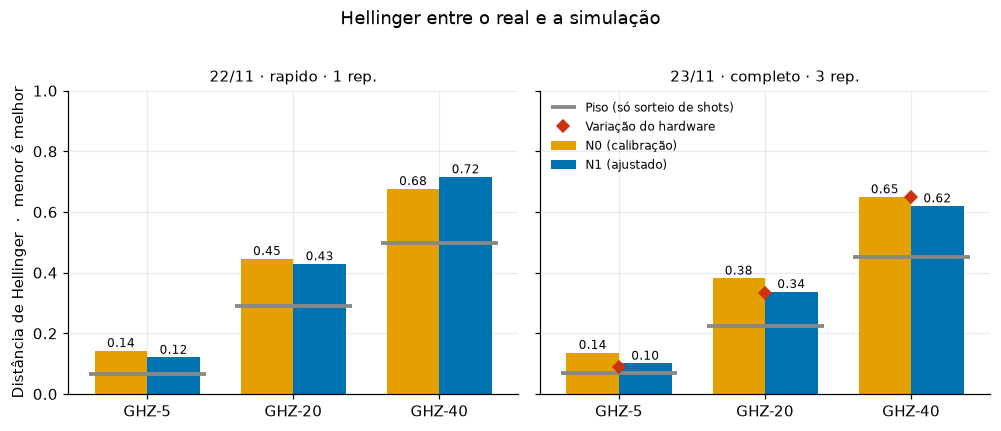

In [9]:
fig, eixos = plt.subplots(1, len(RODADAS), figsize=(4.6 * len(RODADAS), 3.8), sharey=True, squeeze=False)
for ax, (rot, R) in zip(eixos[0], RODADAS.items()):
    nomes = list(R["circ"])
    x = np.arange(len(nomes))
    for k, modelo in enumerate(["N0", "N1"]):
        v = [np.mean(R["circ"][n]["H"][modelo]) for n in nomes]
        ax.bar(x + (k - 0.5) * 0.36, v, 0.36, color=COR[modelo], label=NOME[modelo])
        for xi, vi in zip(x + (k - 0.5) * 0.36, v):
            ax.text(xi, vi + 0.012, f"{vi:.2f}", ha="center", fontsize=8)
    for xi, n in zip(x, nomes):
        ax.hlines(np.mean(R["circ"][n]["piso"]), xi - 0.4, xi + 0.4, color="#888888", lw=2.5,
                  label="Piso (só sorteio de shots)" if xi == 0 else None)
        if R["circ"][n]["hw"] is not None:
            ax.plot(xi, R["circ"][n]["hw"], "D", color="#CC3311", ms=6,
                    label="Variação do hardware" if xi == 0 else None)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("ghz_n", "GHZ-").replace("-0", "-") for n in nomes])
    ax.set_ylim(0, 1)
    ax.set_title(rot, fontsize=10)
eixos[0][0].set_ylabel("Distância de Hellinger  ·  menor é melhor")
h, l = eixos[0][-1].get_legend_handles_labels()
eixos[0][-1].legend(h, l, frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Hellinger entre o real e a simulação", y=1.02)
fig.tight_layout()
salvar(fig, "hellinger")
plt.show()

## 6. Frases-resumo

In [11]:
for rot, R in RODADAS.items():
    print(f"\n{rot}")
    for nome, d in R["circ"].items():
        e0, e1 = erro_massa_pp(d, "N0"), erro_massa_pp(d, "N1")
        h0, h1 = np.mean(d["H"]["N0"]), np.mean(d["H"]["N1"])
        massa = "melhorou" if e1 < e0 else "piorou"
        hell = "melhorou" if h1 < h0 else "piorou"
        fit = " (circuito do ajuste)" if d["ajuste"] else ""
        print(f"  {nome}{fit}: erro da massa {e0:.1f} -> {e1:.1f} pp ({massa}); Hellinger {h0:.3f} -> {h1:.3f} ({hell}).")


22/11 · rapido · 1 rep.
  ghz_n05 (circuito do ajuste): erro da massa 0.4 -> 3.7 pp (piorou); Hellinger 0.143 -> 0.120 (melhorou).
  ghz_n20: erro da massa 11.3 -> 3.4 pp (melhorou); Hellinger 0.446 -> 0.429 (melhorou).
  ghz_n40: erro da massa 11.0 -> 0.8 pp (melhorou); Hellinger 0.677 -> 0.716 (piorou).

23/11 · completo · 3 rep.
  ghz_n05 (circuito do ajuste): erro da massa 5.5 -> 3.8 pp (melhorou); Hellinger 0.137 -> 0.101 (melhorou).
  ghz_n20: erro da massa 15.0 -> 8.5 pp (melhorou); Hellinger 0.381 -> 0.337 (melhorou).
  ghz_n40: erro da massa 16.4 -> 13.8 pp (melhorou); Hellinger 0.650 -> 0.620 (melhorou).
